#Introduction to Jupyter notebook

### Understanding the Introduction

Your notebook begins with an introduction to two key tools:

*   **Jupyter Notebook:** This is the interactive environment (like the one you're using now in Colab) where you can combine live code, explanatory text, equations, and visualizations.
*   **Google Colab:** This is Google's cloud-based service that allows you to use Jupyter Notebooks directly in your browser, often providing free access to powerful hardware like GPUs.

What is Jupyter Notebook?

Jupyter Notebook is an open-source web application that allows you to create and share documents that contain live code, equations, visualizations, and narrative text. It is widely used for data analysis, scientific computing, and machine learning due to its interactive nature.



What is Google Colab?

Google Colab (short for Colaboratory) is a cloud-based service that allows you to run Jupyter Notebooks in your browser without the need to install anything locally. It provides free access to GPUs and TPUs, making it a powerful tool for machine learning and data analysis tasks.

### Required Libraries

This section (`#requiered libraries`) sets up the necessary Python packages for your simulations and plotting.

#requiered libraries

First, the `pip install` cell ensures that `numpy` and `matplotlib` are available in your environment. These are fundamental libraries:

*   **`numpy` (Numerical Python):** Essential for numerical operations, especially with arrays and mathematical functions, which are heavily used in scientific computing.
*   **`matplotlib`:** A comprehensive library for creating static, animated, and interactive visualizations in Python.

In [ ]:
pip install numpy matplotlib


Next, the `import` cell makes these libraries and a few others available for use in your Python code:

*   **`import numpy as np`:** Imports NumPy and gives it the alias `np`, which is a common convention.
*   **`import matplotlib.pyplot as plt`:** Imports the `pyplot` module from Matplotlib, typically aliased as `plt`, for plotting functions.
*   **`from scipy.stats import gamma`:** Imports the `gamma` function from SciPy's statistics module, which is used for working with the Gamma distribution, particularly for generating random numbers following this distribution.
*   **`from collections import deque`:** Imports `deque` (double-ended queue) from the `collections` module. This data structure allows for efficient appending and popping from both ends, which is useful for managing time-ordered events, especially in the delayed Gillespie algorithm.

In [ ]:
import numpy as np                 # NumPy provides arrays and numerical operations.
import matplotlib.pyplot as plt    # Matplotlib renders plots and figures.
from scipy.stats import gamma      # scipy.stats.gamma supplies Gamma distribution functions.
from collections import deque      # deque offers a fast double-ended queue for appending and popping from both ends.


### Part 1: Simulating Population Dynamics with the Gillespie Algorithm

This first major part of the assignment focuses on simulating a predator-prey system (sheep and wolves) using the Gillespie algorithm, a stochastic simulation method. You'll observe how populations change over time based on defined reaction rates.

#Part1:

#### The Reaction System

The image describes a simple ecological model with three reactions:

1.  **Sheep Reproduction:** Sheep reproduce at a rate `c_eatgrass`.
    *   `Sheep --(c_eatgrass)--> Sheep + 1`
2.  **Wolves Eat Sheep (Wolf Reproduction):** Wolves eat sheep, leading to a decrease in sheep and an increase in wolves, at a rate `c_eatsheep`.
    *   `Sheep + Wolf --(c_eatsheep)--> Wolf + 1`
3.  **Wolf Starvation:** Wolves die of starvation at a rate `c_starve`.
    *   `Wolf --(c_starve)--> Wolf - 1`

The initial parameters are set: `c_eatgrass = 10`, `c_eatsheep = 0.01`, and `c_starve = 10`. The simulation runs until `t = 10` time units, and you're asked to plot the populations.

Simulate this reaction system:
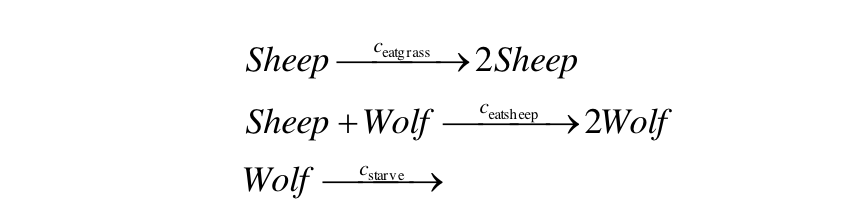

Set ceatgrass to 10, ceatsheep to 0.01 and cstarve to 10. Run the
simulation until t = 10, sampling every 0.01 time units and plot the number of wolves and number
of sheep over time.


#### Deterministic vs. Stochastic Models

This section explains the difference between two fundamental types of models:

*   **Deterministic Models:** These models produce the same output for the same input every time. They use fixed equations and are often suitable for large systems where random fluctuations are less significant.
*   **Stochastic Models:** These models incorporate randomness, meaning their outputs can vary even with the same inputs. They are crucial for systems where random events play a significant role, like biological processes with small numbers of molecules or individuals.

## Deterministic VS Stochastic

#### The Gillespie Algorithm

This section provides a detailed explanation of the Gillespie algorithm, which is a method for performing **stochastic simulations** of chemical reactions or other discrete events. Here's a summary of its steps:

1.  **Define the System:** Specify all possible reactions and their rates.
2.  **Initialize:** Set up the starting conditions (e.g., initial populations).
3.  **Calculate Propensities:** Determine the likelihood (propensity) of each reaction occurring given the current state of the system.
4.  **Generate Random Numbers:** Use two random numbers:
    *   One to decide *which* reaction will occur next.
    *   One to determine *when* that reaction will occur (the time increment).
5.  **Update System:** Execute the chosen reaction and update the system's state (e.g., change populations) and the simulation time.
6.  **Repeat:** Continue steps 3-5 until the simulation ends.


Deterministic models use fixed equations to predict system behavior, always giving the same result for the same inputs. They are best for large-scale systems where random variation is negligible.

Stochastic models include randomness in how events occur, so results can differ between runs. They are useful for capturing variability and uncertainty in real-world systems, especially when dealing with small numbers or noisy processes.

##Gillespie algorithm

#### Part 1 Simulation Code: The `gillespie` Function

This is the core Python code for simulating the sheep-wolf dynamics using the Gillespie algorithm.

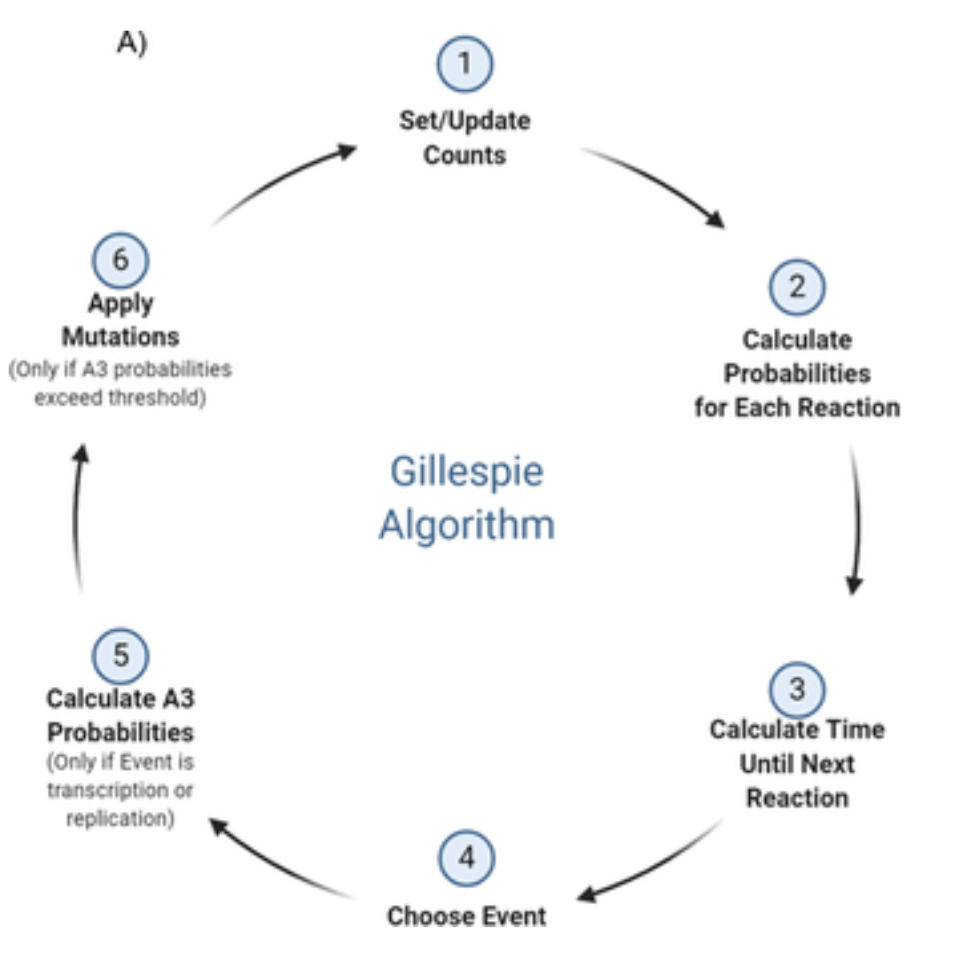

The Gillespie algorithm, also known as the Gillespie stochastic simulation algorithm (SSA), is a numerical method used to simulate the time evolution of chemical reactions or other stochastic processes in systems with a large number of discrete events. It's particularly useful for systems where the random nature of the events plays a significant role, such as in biochemical networks, ecological models, and more.

Here’s a high-level overview of how the Gillespie algorithm works:

Define the System: Specify the chemical reactions or events and their associated rates. The system is described by a set of reactions, each with a rate constant and reactants/products.

Initialize the System: Start with an initial configuration of the system, which includes the initial quantities of each reactant or species.

Calculate Propensities: Compute the propensity functions for each reaction. The propensity function is a measure of how likely each reaction is to occur in a given time step, based on the current state of the system.

Generate Random Numbers: Use random numbers to determine which reaction will occur and when it will happen. This involves generating two random numbers:
One to determine which reaction will take place.
Another to determine the time until the reaction occurs.

Update the System: Perform the chosen reaction and update the state of the system accordingly. Increase the simulation time by the amount determined in step 4.

Repeat: Repeat the process from step 3 until the simulation reaches the desired end time or condition.

Let's break down the `gillespie` function:

*   **Input Parameters:**
    *   `Sheep0`, `Wolf0`: Initial populations of sheep and wolves.
    *   `c_eatgrass`, `c_eatsheep`, `c_starve`: The rate constants for the three reactions.
    *   `time_end`: The total duration for the simulation.
    *   `dt`: A time step (though not directly used in this specific Gillespie implementation, it's often a parameter in other simulation methods).

*   **Initialization:**
    *   `times`, `sheep`, `wolves`: Lists are created to store the state of the system at each reaction event. They start with the initial time and populations.
    *   `Sheep`, `Wolf`, `time`: Variables to track the current state.
    *   `reaction_counter`: A safety mechanism to prevent infinite loops in very long simulations.

*   **Simulation Loop (`while time < time_end`):**
    *   **Calculate Reaction Rates:** `r1`, `r2`, `r3` are calculated based on the current populations and rate constants. `total_rate` is the sum of these, representing the overall likelihood of *any* reaction occurring.
    *   **Handle Zero Rate:** If `total_rate` is 0, no reactions can happen, so the simulation stops.
    *   **Determine Time to Next Reaction (`tau`):** `tau = -np.log(np.random.rand()) / total_rate` calculates the time until the next reaction. This is derived from the exponential distribution, characteristic of Poisson processes which govern these types of stochastic events.
    *   **Update Time:** The current `time` is advanced by `tau`.
    *   **Check End Time:** If the new `time` exceeds `time_end`, the simulation stops.
    *   **Determine Which Reaction Occurs:** A random number `prob` is generated. By comparing `prob` to cumulative sums of the individual reaction rates, the specific reaction (sheep reproduce, wolf eats sheep, or wolf starves) is chosen.
    *   **Update Populations:** The chosen reaction changes the `Sheep` and `Wolf` counts accordingly.
    *   **Record State:** The current `time`, `Sheep`, and `Wolf` counts are appended to their respective lists.
    *   **Safety Counter:** The `reaction_counter` is incremented, and the loop breaks if it exceeds a limit.

*   **Return Value:** The function returns NumPy arrays of `times`, `sheep`, and `wolves` populations.

##Part1 Simulation

#### Running and Plotting the Initial Simulation

After defining the `gillespie` function, the notebook sets the initial conditions and parameters (`Sheep0`, `Wolf0`, `time_end`, `dt`) and then calls the `gillespie` function to run the simulation.

The `plt.figure`, `plt.plot`, `plt.xlabel`, `plt.ylabel`, `plt.title`, `plt.legend`, `plt.grid`, and `plt.show` commands are standard Matplotlib functions used to create and display a clear plot of the sheep and wolf populations over time.

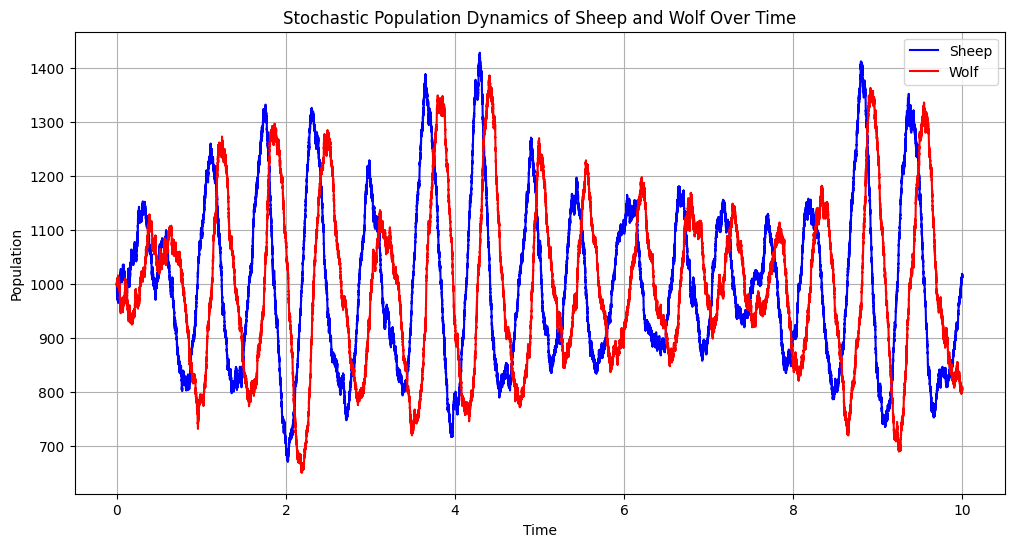

In [7]:
# Define parameters for the model
c_eatgrass = 10   # Rate of sheep reproduction due to eating grass
c_eatsheep = 0.01 # Rate of wolves eating sheep
c_starve = 10     # Rate of wolves dying due to starvation

# Define the Gillespie algorithm function for stochastic simulation
def gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt):
    # Initialize lists to store the time points and populations of sheep and wolves
    times = [0]        # List to store the simulation times
    sheep = [Sheep0]   # List to store the sheep population over time
    wolves = [Wolf0]   # List to store the wolf population over time

    # Initialize variables for the current populations and time
    Sheep = Sheep0     # Current number of sheep
    Wolf = Wolf0       # Current number of wolves
    time = 0           # Initialize time at 0
    reaction_counter = 0 # Counter to limit the number of reactions

    # Run the simulation loop until the specified end time
    while time < time_end:
        # Calculate the rates of each reaction
        r1 = c_eatgrass * Sheep               # Rate of sheep reproduction
        r2 = c_eatsheep * Sheep * Wolf        # Rate of wolves eating sheep
        r3 = c_starve * Wolf                  # Rate of wolves dying

        total_rate = r1 + r2 + r3             # Total rate of all reactions

        # If the total rate is 0, break out of the loop (no reactions possible)
        if total_rate == 0:
            break

        # Calculate time to the next reaction based on exponential distribution
        tau = -np.log(np.random.rand()) / total_rate
        time += tau  # Update the current time with the time increment

        # If the next reaction time exceeds the end time, break out of the loop
        if time >= time_end:
            break

        # Determine which reaction occurs based on random sampling
        prob = np.random.rand() * total_rate # Generate a random number to determine the reaction type
        if prob < r1:
            Sheep += 1  # Sheep reproduce
        elif prob < r1 + r2:
            Sheep -= 1  # A sheep is eaten by a wolf
            Wolf += 1   # The wolf population increases
        else:
            Wolf -= 1   # A wolf dies of starvation

        # Record the current state (time, sheep, wolves) after the reaction
        times.append(time)
        sheep.append(Sheep)
        wolves.append(Wolf)
        reaction_counter += 1

        # Safety check to prevent too many iterations (for performance)
        if reaction_counter > 500000:
            break

    # Return the time and population lists as numpy arrays
    return np.array(times), np.array(sheep), np.array(wolves)

# Initial conditions and parameters for the simulation
Sheep0 = 1000    # Initial number of sheep
Wolf0 = 1000     # Initial number of wolves
time_end = 10    # Total simulation time
dt = 0.01        # Time step (not used in this function, but could be needed elsewhere)

# Run the Gillespie simulation with the defined parameters
times, sheep, wolves = gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt)

# Plot the results of the simulation
plt.figure(figsize=(12, 6))  # Create a new figure with a defined size
plt.plot(times, sheep, label='Sheep', color='b')  # Plot sheep population over time
plt.plot(times, wolves, label='Wolf', color='r')  # Plot wolf population over time
plt.xlabel('Time')  # Label for the x-axis
plt.ylabel('Population')  # Label for the y-axis
plt.title('Stochastic Population Dynamics of Sheep and Wolf Over Time')  # Plot title
plt.legend()  # Show legend
plt.grid(True)  # Show grid for better visualization
plt.show()  # Display the plot


In [6]:

# Check the population values being plotted
print("Starting sheep:", sheep[0])
print("Starting wolves:", wolves[0])
print("Number of data points:", len(sheep))

Starting sheep: 1000.0
Starting wolves: 1200.0
Number of data points: 1000


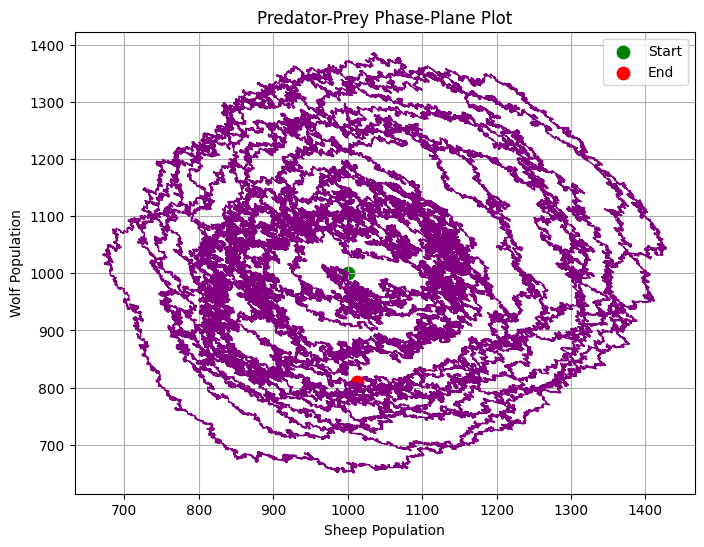

In [8]:

# Additional Plot: Predator-Prey Phase Plane
# Uses the sheep and wolf populations from the simulation

plt.figure(figsize=(8, 6))

# Plot wolf population against sheep population
plt.plot(sheep, wolves, color='purple', linewidth=1)

# Mark the starting population
plt.scatter(sheep[0], wolves[0],
            color='green', s=80, label='Start')

# Mark the final population
plt.scatter(sheep[-1], wolves[-1],
            color='red', s=80, label='End')

# Label the graph
plt.xlabel('Sheep Population')
plt.ylabel('Wolf Population')
plt.title('Predator-Prey Phase-Plane Plot')
plt.legend()
plt.grid(True)

# Display the graph
plt.show()

### Additional Visualization: Predator–Prey Phase-Plane Analysis

The phase-plane graph illustrates the relationship between sheep and wolf populations during the stochastic simulation. Unlike the original time-series graph, this visualization compares the two populations directly. The irregular, overlapping loops demonstrate repeated predator–prey cycles, where changes in the sheep population are associated with changes in the wolf population. The variations in the loops reflect the randomness incorporated into the Gillespie simulation. Overall, this graph provides an additional way to visualize the dynamic relationship between predator and prey populations.

##Decrease the rate of wolves dying

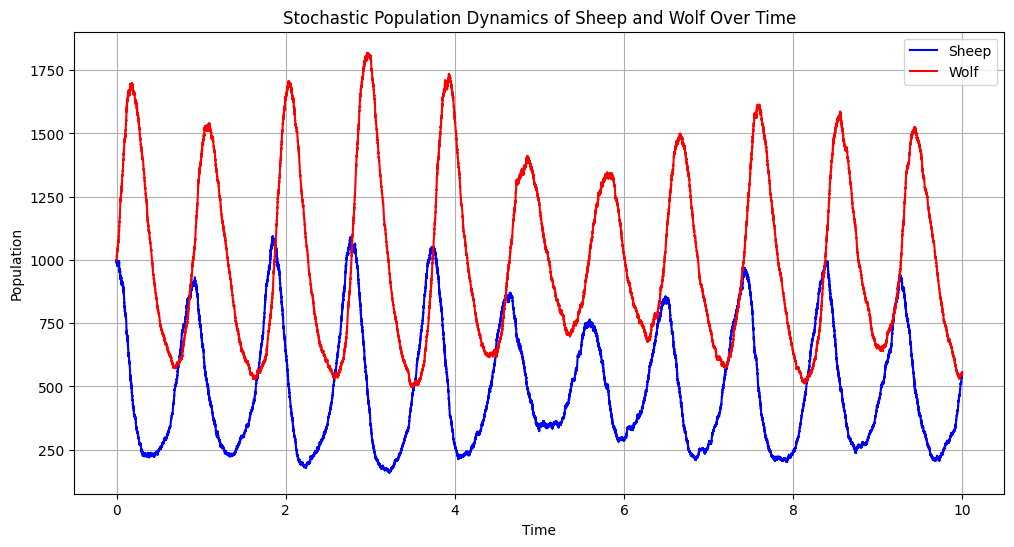

In [10]:
# Define parameters
c_eatgrass = 10   # Rate of sheep reproduction due to grass
c_eatsheep = 0.01 # Rate of wolves eating sheep
c_starve = 5     # Rate of wolves dying
# Initial conditions and parameters
Sheep0 = 1000
Wolf0 = 1000
time_end = 10
dt = 0.01

# Run simulation
times, sheep, wolves = gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(times, sheep, label='Sheep', color='b')
plt.plot(times, wolves, label='Wolf', color='r')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Stochastic Population Dynamics of Sheep and Wolf Over Time')
plt.legend()
plt.grid(True)
plt.show()

### Experiment 1: Effect of Decreasing the Wolf Death Rate

**Hypothesis:** Decreasing the wolf death-rate parameter will allow wolves to survive longer, potentially increasing the wolf population and reducing the sheep population through increased predation.

**Results and Interpretation:** The wolf death-rate parameter was reduced from 10 to 5. The simulation showed repeated oscillations in both populations, with wolf population peaks reaching approximately 1,800 individuals and sheep population lows approaching 200 individuals. The wolf population generally remained higher than the sheep population during much of the simulation. These results are consistent with the expectation that reduced wolf mortality can increase predator abundance and predation pressure on sheep. Because the model is stochastic, additional simulation runs would be needed to determine how consistently this pattern occurs.

Experiment 1: Effect of Decreasing the Wolf Death Rate

##Decrease the rate of sheep reproduction

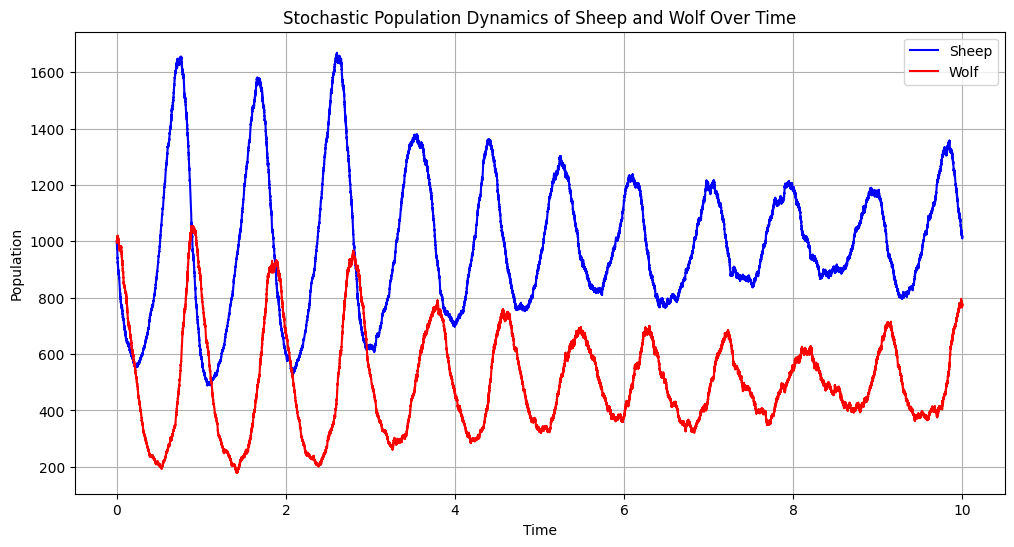

In [11]:
# Define parameters
c_eatgrass = 5   # Rate of sheep reproduction due to grass
c_eatsheep = 0.01 # Rate of wolves eating sheep
c_starve = 10     # Rate of wolves starving if no sheep
# Initial conditions and parameters
Sheep0 = 1000
Wolf0 = 1000
time_end = 10
dt = 0.01

# Run simulation
times, sheep, wolves = gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(times, sheep, label='Sheep', color='b')
plt.plot(times, wolves, label='Wolf', color='r')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Stochastic Population Dynamics of Sheep and Wolf Over Time')
plt.legend()
plt.grid(True)
plt.show()

### Experiment 2: Effect of Decreasing Sheep Reproduction

**Hypothesis:** Decreasing the sheep reproduction rate will reduce the growth of the sheep population and may indirectly affect the wolf population by limiting food availability.

**Results and Interpretation:** The simulation demonstrated repeated oscillations in both sheep and wolf populations after decreasing the sheep reproduction rate. The sheep population reached peaks of approximately 1,650 individuals, while the wolf population fluctuated between approximately 200 and 1,050 individuals. Although sheep reproduction was reduced, the sheep population continued to recover during several cycles. This may be explained by the interaction between predator and prey populations, where lower wolf abundance can reduce predation pressure and allow sheep to recover. Overall, the results demonstrate that population dynamics depend on multiple interacting biological processes rather than reproduction rates alone.

##Decrease the rate of wolves eating sheep (wolves reproduction)

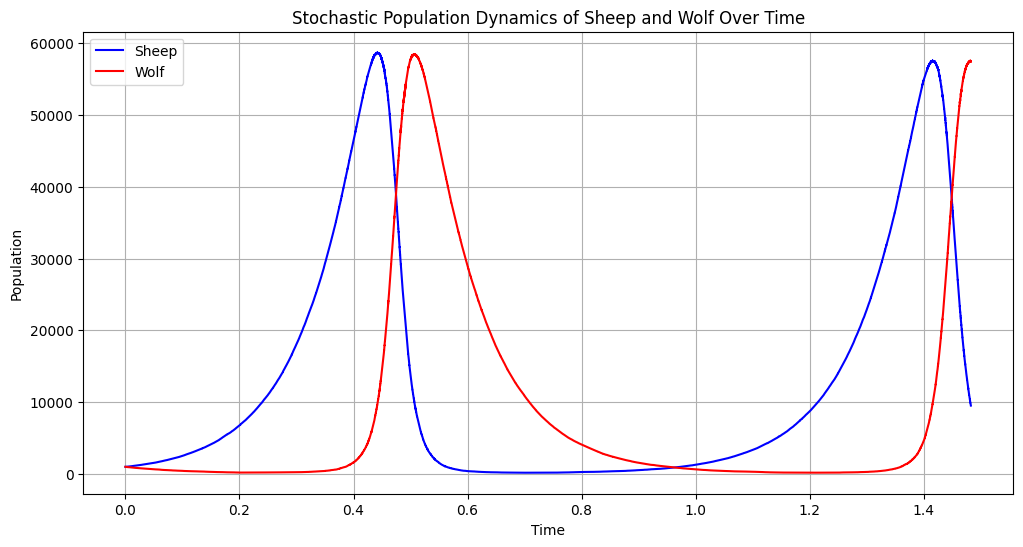

In [12]:
# Define parameters
c_eatgrass = 10   # Rate of sheep reproduction due to grass
c_eatsheep = 0.001 # Rate of wolves eating sheep
c_starve = 10     # Rate of wolves starving if no sheep
# Initial conditions and parameters
Sheep0 = 1000
Wolf0 = 1000
time_end = 10
dt = 0.01

# Run simulation
times, sheep, wolves = gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(times, sheep, label='Sheep', color='b')
plt.plot(times, wolves, label='Wolf', color='r')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Stochastic Population Dynamics of Sheep and Wolf Over Time')
plt.legend()
plt.grid(True)
plt.show()

### Experiment 3: Effect of Decreasing the Rate of Wolves Eating Sheep

**Hypothesis:** Decreasing the rate of wolves eating sheep will reduce predation pressure, allowing the sheep population to increase while potentially delaying wolf population growth.

**Results and Interpretation:** The simulation showed substantial changes in the predator–prey population dynamics after decreasing the predation reaction rate. The sheep population increased rapidly, reaching approximately 58,000 individuals before declining sharply. The wolf population increased shortly afterward, also reaching approximately 58,000 individuals. These results suggest that reduced predation initially allows sheep to reproduce and accumulate, creating a larger food supply that can subsequently support rapid wolf population growth. As the wolf population increases, the sheep population decreases, followed by a decline in wolves. The results demonstrate how changes in predation rates can influence population size, oscillation amplitude, and the timing of predator–prey interactions. The populations do not necessarily increase at the same time. The sheep population peaks first, followed by the wolf population. This delay helps explain how predator–prey relationships produce oscillations.

##Increase the rate of wolves eating sheep (wolves reproduction)

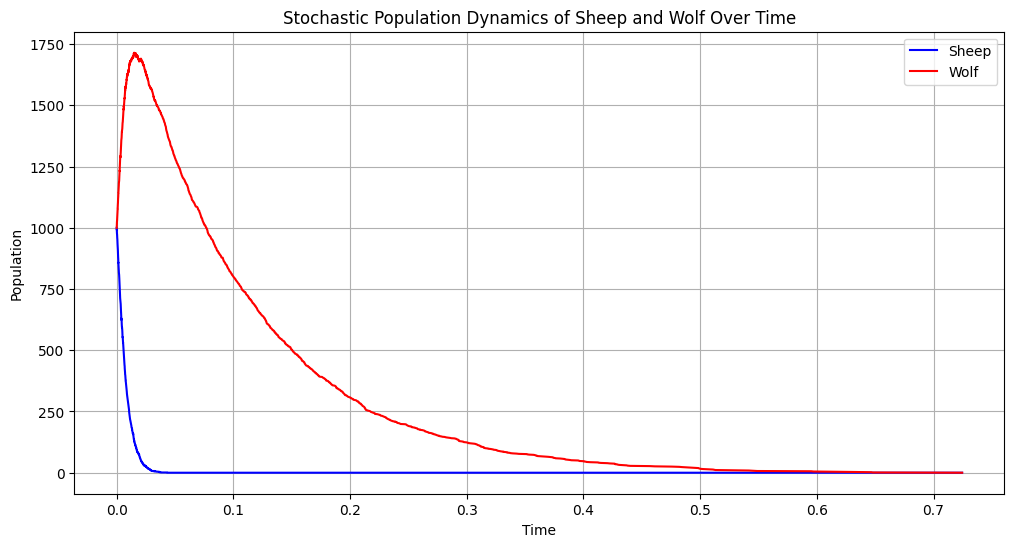

In [13]:
# Define parameters
c_eatgrass = 10   # Rate of sheep reproduction due to grass
c_eatsheep = 0.1 # Rate of wolves eating sheep
c_starve = 10     # Rate of wolves starving if no sheep
# Initial conditions and parameters
Sheep0 = 1000
Wolf0 = 1000
time_end = 10
dt = 0.01

# Run simulation
times, sheep, wolves = gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(times, sheep, label='Sheep', color='b')
plt.plot(times, wolves, label='Wolf', color='r')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Stochastic Population Dynamics of Sheep and Wolf Over Time')
plt.legend()
plt.grid(True)
plt.show()

### Experiment 4: Effect of Increasing the Rate of Wolves Eating Sheep

**Hypothesis:** Increasing the predation reaction rate will cause the sheep population to decrease more rapidly while initially supporting wolf population growth through increased feeding and reproduction events.

**Results and Interpretation:** The simulation demonstrated a rapid decline in the sheep population after increasing the predation reaction rate. The sheep population decreased from approximately 1,000 individuals to nearly zero early in the simulation. Meanwhile, the wolf population initially increased to approximately 1,700 individuals before gradually declining toward zero. These results suggest that increased predation initially benefits wolves but can rapidly deplete the available prey population. As sheep become scarce, the wolf population declines because of reduced food availability and continued mortality. Overall, this experiment demonstrates how excessive predation can destabilize predator–prey dynamics and potentially lead to population collapse.

##what if we only had 1 sheep in the beginning

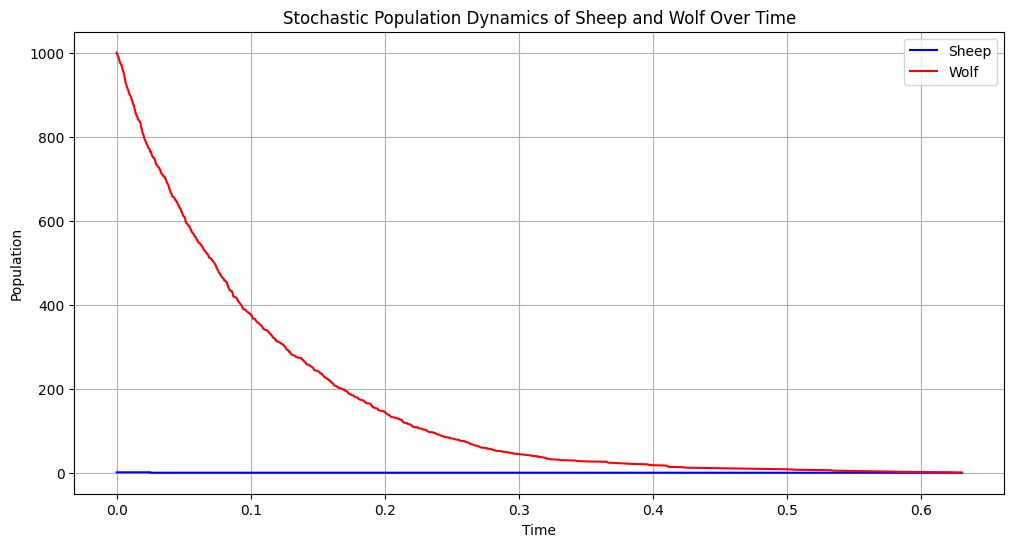

In [15]:
# Define parameters
c_eatgrass = 10   # Rate of sheep reproduction due to grass
c_eatsheep = 0.01 # Rate of wolves eating sheep
c_starve = 10     # Rate of wolves starving if no sheep
# Initial conditions and parameters
Sheep0 = 1
Wolf0 = 1000
time_end = 10
dt = 0.01

# Run simulation
times, sheep, wolves = gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(times, sheep, label='Sheep', color='b')
plt.plot(times, wolves, label='Wolf', color='r')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Stochastic Population Dynamics of Sheep and Wolf Over Time')
plt.legend()
plt.grid(True)
plt.show()

### Experiment 5: Effect of Starting With One Sheep

**Hypothesis:** Starting the simulation with only one sheep and approximately 1,000 wolves will make the sheep population highly vulnerable to extinction, potentially causing the wolf population to decline because of limited food availability.

**Results and Interpretation:** The simulation showed that the sheep population remained near zero while the wolf population steadily declined from approximately 1,000 individuals toward zero. The results are consistent with the expectation that an extremely small prey population may be unable to sustain a large predator population. Once the sheep population becomes depleted, wolves have insufficient prey available to support continued population growth. This experiment demonstrates the importance of initial population size and prey availability in maintaining predator–prey dynamics.

##what if we only had 1 Wolf in the beginning

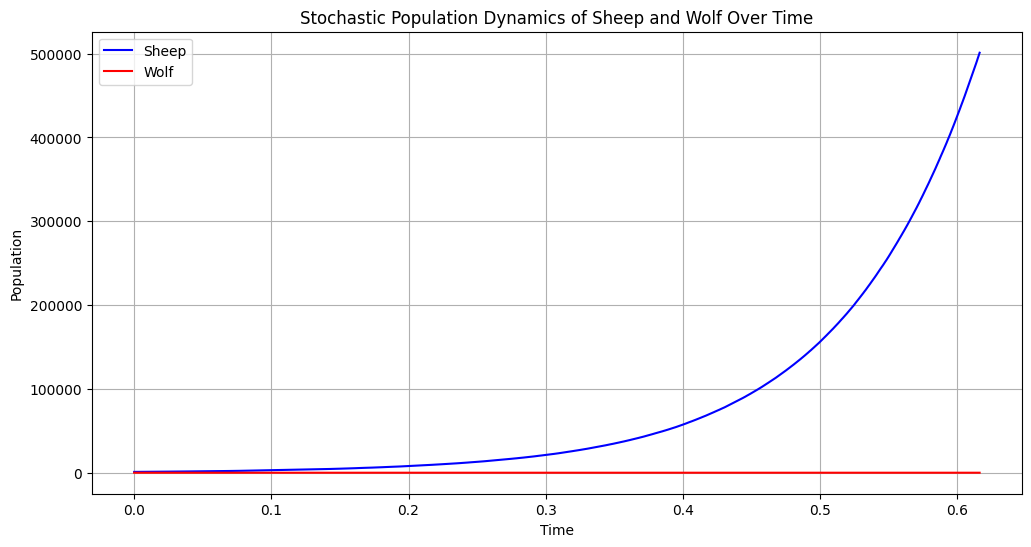

In [18]:
# Define parameters
c_eatgrass = 10   # Rate of sheep reproduction due to grass
c_eatsheep = 0.01 # Rate of wolves eating sheep
c_starve = 10     # Rate of wolves starving if no sheep
# Initial conditions and parameters
Sheep0 = 1000
Wolf0 = 1
time_end = 10
dt = 0.01

# Run simulation
times, sheep, wolves = gillespie(Sheep0, Wolf0, c_eatgrass, c_eatsheep, c_starve, time_end, dt)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(times, sheep, label='Sheep', color='b')
plt.plot(times, wolves, label='Wolf', color='r')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Stochastic Population Dynamics of Sheep and Wolf Over Time')
plt.legend()
plt.grid(True)
plt.show()

Starting wolves: 1
Ending wolves: 0


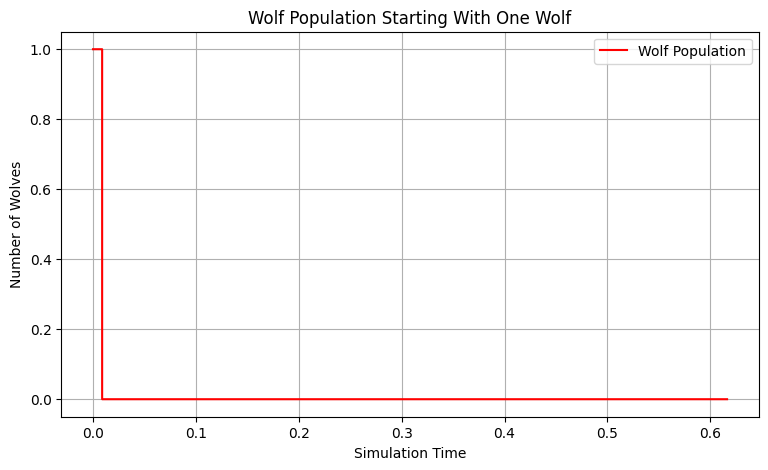

In [19]:

# Additional visualization for the one-wolf experiment
# Save the results so later simulations do not overwrite them

one_wolf_times = times.copy()
one_wolf_population = wolves.copy()

# Check the starting and ending wolf populations
print("Starting wolves:", one_wolf_population[0])
print("Ending wolves:", one_wolf_population[-1])

# Plot wolves against actual simulation time
plt.figure(figsize=(9, 5))

plt.plot(one_wolf_times, one_wolf_population,
         color='red', label='Wolf Population')

plt.xlabel('Simulation Time')
plt.ylabel('Number of Wolves')
plt.title('Wolf Population Starting With One Wolf')
plt.legend()
plt.grid(True)
plt.show()

### Experiment 6: Effect of Starting With One Wolf

**Hypothesis:** Starting with only one wolf and approximately 1,000 sheep will reduce predation pressure, allowing the sheep population to increase if the wolf fails to survive and reproduce.

**Results and Interpretation:** The simulation began with 1,000 sheep and one wolf. The additional wolf-population graph confirmed that the single wolf died early in the simulation, reducing the wolf population from one to zero. Without predators, the sheep population increased rapidly, reaching approximately 500,000 individuals by the end of the displayed simulation. These results demonstrate how stochastic extinction of a small predator population can influence the growth of prey populations. The experiment also highlights the importance of initial population size and random events in biological modeling.

# Part2

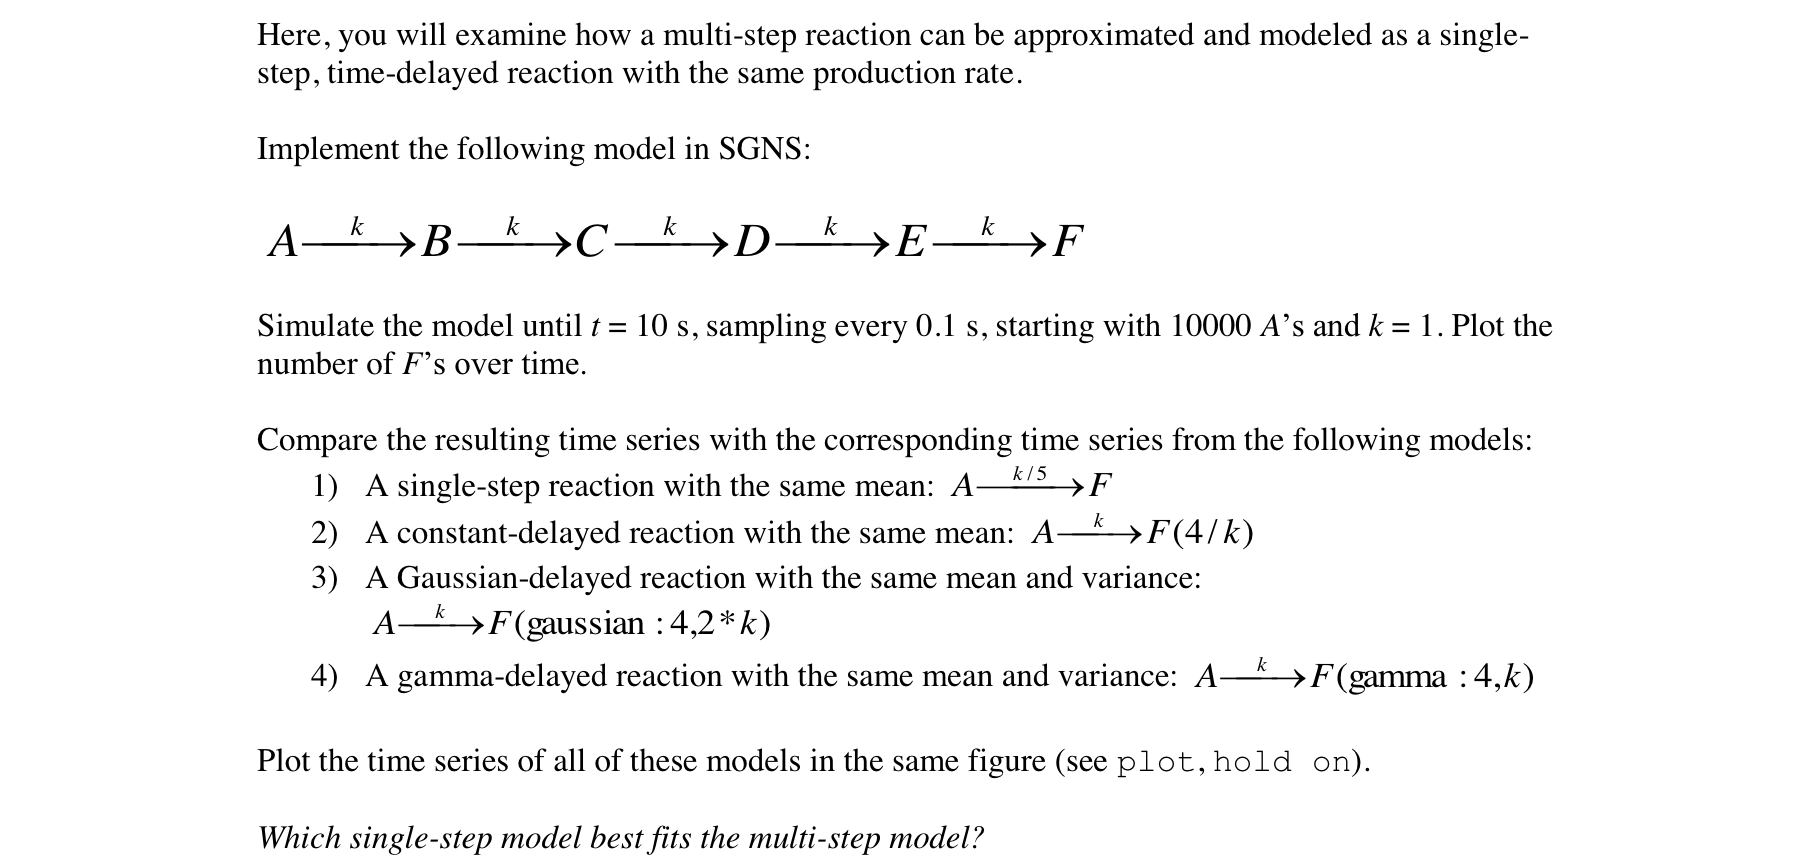

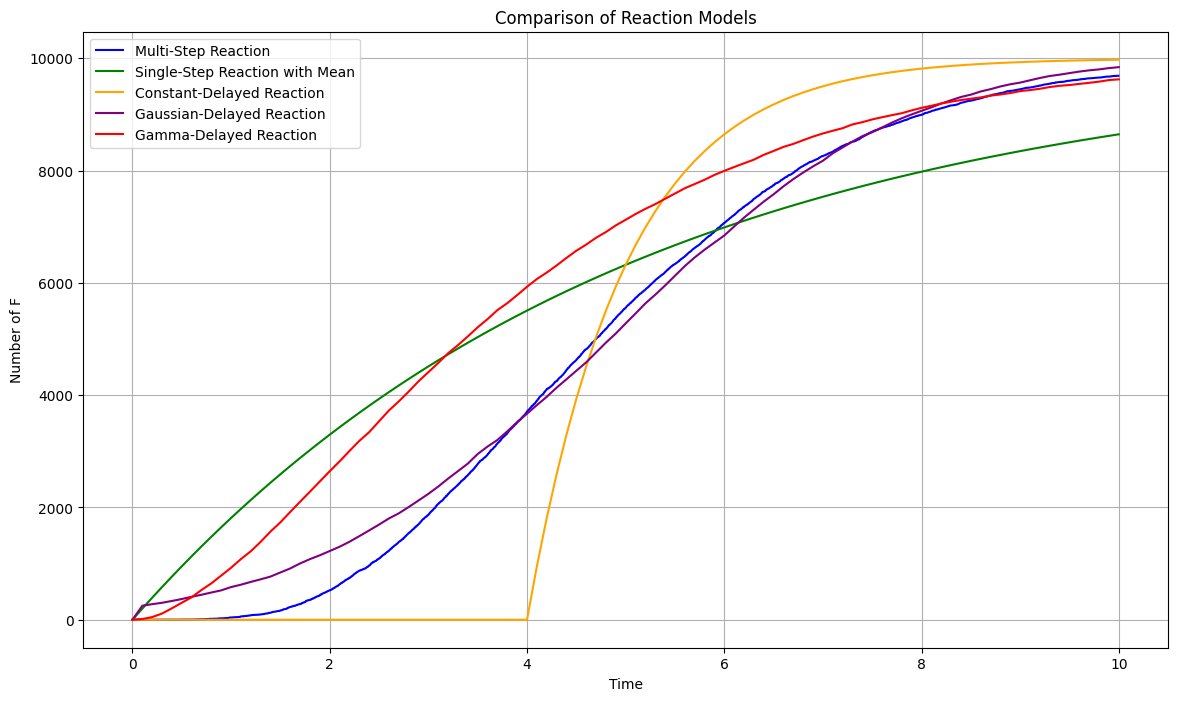

In [22]:
from scipy.stats import gamma
import numpy as np
import matplotlib.pyplot as plt

# General Multi-Step Reaction Model
def multi_step_reaction(A0, k, time_end, dt):
    # Initialize time and product arrays
    times = [0]  # Store time points
    F = [0]      # Store product F values over time

    # Initialize reactants and products
    A = A0       # Initial amount of reactant A
    B = C = D = E = 0  # Initial amounts of intermediate products
    F_val = 0    # Initial amount of final product F
    time = 0     # Initialize time

    # Continue until the simulation reaches the end time
    while time < time_end:
        # Calculate reaction rates for each step
        rate_A_to_B = k * A
        rate_B_to_C = k * B
        rate_C_to_D = k * C
        rate_D_to_E = k * D
        rate_E_to_F = k * E

        # Total reaction rate
        total_rate = rate_A_to_B + rate_B_to_C + rate_C_to_D + rate_D_to_E + rate_E_to_F

        # If total rate is zero, stop the simulation
        if total_rate == 0:
            break

        # Compute time increment based on total rate
        tau = -np.log(np.random.rand()) / total_rate
        time += tau  # Increment the time

        # Break if time exceeds the end time
        if time >= time_end:
            break

        # Randomly determine which reaction step occurs
        prob = np.random.rand() * total_rate
        if prob < rate_A_to_B:
            B += 1
            A -= 1
        elif prob < rate_A_to_B + rate_B_to_C:
            C += 1
            B -= 1
        elif prob < rate_A_to_B + rate_B_to_C + rate_C_to_D:
            D += 1
            C -= 1
        elif prob < rate_A_to_B + rate_B_to_C + rate_C_to_D + rate_D_to_E:
            E += 1
            D -= 1
        else:
            F_val += 1
            E -= 1

        # Store time and product values
        times.append(time)
        F.append(F_val)

    return np.array(times), np.array(F)

# General Single-Step Reaction with Mean
def single_step_mean(A0, k, time_end, dt, rate_fraction):
    # Create time array
    times = np.arange(0, time_end + dt, dt)
    F = np.zeros_like(times)  # Initialize product array

    rate = k * rate_fraction  # Effective rate for single-step reaction
    # Compute the number of products over time
    for i, t in enumerate(times):
        F[i] = A0 * (1 - np.exp(-rate * t))

    return times, F

# General Constant-Delayed Reaction
def constant_delayed(A0, k, time_end, dt, delay_fraction):
    # Create time array
    times = np.arange(0, time_end + dt, dt)
    F = np.zeros_like(times)  # Initialize product array

    delay = delay_fraction / k  # Calculate delay time
    # Compute the number of products after the delay
    for i, t in enumerate(times):
        if t >= delay:
            F[i] = A0 * (1 - np.exp(-k * (t - delay)))

    return times, F

# General Gaussian-Delayed Reaction
def gaussian_delayed_reaction(A0, k, mean_delay, std_delay, t_end, dt):
    # Create time array
    times = np.arange(0, t_end + dt, dt)
    F = np.zeros_like(times)  # Initialize product array
    A = np.zeros_like(times)  # Initialize reactant array
    A[0] = A0  # Set initial amount of reactant A

    # Generate reaction times with Gaussian delays
    reaction_times = np.random.normal(mean_delay, std_delay, size=A0) * 1.2
    reaction_times = np.clip(reaction_times, 0, t_end)  # Ensure delays are within the simulation time

    # Sort reaction times for efficient processing
    reaction_times.sort()

    # Index for tracking which reaction time to process
    reaction_idx = 0
    num_reactions = len(reaction_times)

    # Iterate over time points
    for t_idx in range(1, len(times)):
        # Process all reactions whose delays have passed
        while reaction_idx < num_reactions and reaction_times[reaction_idx] < times[t_idx]:
            if A[t_idx-1] > 0:
                F[t_idx] += k  # Increment product count
                A[t_idx] = A[t_idx-1] - F[t_idx]  # Decrease reactant count
            reaction_idx += 1
        A[t_idx] = max(A[t_idx], 0)  # Ensure no negative concentration

    return times, F

# General Gamma-Delayed Reaction
def gamma_delayed_reaction(A0, k, shape, scale, t_end, dt):
    # Create time array
    times = np.arange(0, t_end + dt, dt)
    F = np.zeros_like(times)  # Initialize product array
    A = np.zeros_like(times)  # Initialize reactant array
    A[0] = A0  # Set initial amount of reactant A

    # Generate reaction times with Gamma delays
    reaction_times2 = gamma.rvs(shape, scale=scale, size=A0)
    reaction_times2 = np.clip(reaction_times2, 0, t_end)  # Ensure delays are within the simulation time

    # Sort reaction times for efficient processing
    reaction_times2.sort()

    # Index for tracking which reaction time to process
    reaction_idx = 0
    num_reactions = len(reaction_times2)

    # Iterate over time points
    for t_idx in range(1, len(times)):
        # Process all reactions whose delays have passed
        while reaction_idx < num_reactions and reaction_times2[reaction_idx] < times[t_idx]:
            if A[t_idx-1] > 0:
                F[t_idx] += k  # Increment product count
                A[t_idx] = A[t_idx-1] - F[t_idx]  # Decrease reactant count
            reaction_idx += 1
        A[t_idx] = max(A[t_idx], 0)  # Ensure no negative concentration

    return times, F

# Parameters for the simulation
A0 = 10000  # Initial amount of reactant A
k = 1       # Rate constant
time_end = 10  # End time of the simulation
dt = 0.1    # Time step for the simulation

# Run simulations with different models
times, F_multi = multi_step_reaction(A0, k, time_end, dt)
times_mean, F_mean = single_step_mean(A0, k, time_end, dt, rate_fraction=1/5)
times_const, F_const = constant_delayed(A0, k, time_end, dt, delay_fraction=4)
times_gauss, F_gauss = gaussian_delayed_reaction(A0, k, 4, 2, time_end, dt)
times_gamma, F_gamma = gamma_delayed_reaction(A0, k, 2, 2, time_end, dt)

# Plotting the results
plt.figure(figsize=(14, 8))

plt.plot(times, F_multi, label='Multi-Step Reaction', color='blue')
plt.plot(times_mean, F_mean, label='Single-Step Reaction with Mean', color='green')
plt.plot(times_const, F_const, label='Constant-Delayed Reaction', color='orange')
plt.plot(times_gauss, np.cumsum(F_gauss), label='Gaussian-Delayed Reaction', color='purple')
plt.plot(times_gamma, np.cumsum(F_gamma), label='Gamma-Delayed Reaction', color='red')

plt.xlabel('Time')
plt.ylabel('Number of F')
plt.title('Comparison of Reaction Models')
plt.legend()
plt.grid(True)
plt.show()

### Part 2: Comparison of Reaction Models

**Objective:** To compare how different reaction mechanisms and delay distributions affect the accumulation of final product F over time.

**Results and Interpretation:** The graph compares five reaction models: multi-step, single-step with mean, constant-delayed, Gaussian-delayed, and gamma-delayed reactions. Each model produces a different accumulation pattern for final product F. The multi-step model initially shows slower product formation before accelerating, while the single-step model produces F immediately but accumulates more gradually. The constant-delayed model shows no product formation until approximately time 4, followed by a rapid increase. The Gaussian- and gamma-delayed models demonstrate how variation in reaction completion times influences the accumulation of F.

Overall, the results indicate that reaction mechanisms and delay distributions influence when the final product becomes available. These differences are important when modeling biological processes involving multiple reaction steps, intermediate molecules, or delayed responses.

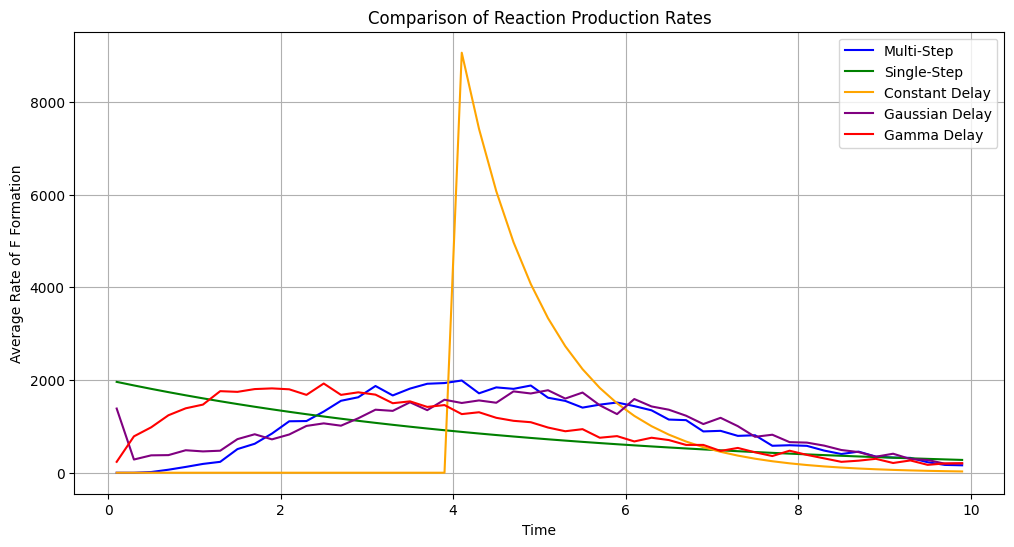

In [24]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate average production rates over equal time intervals
# This avoids very large spikes from tiny stochastic time steps

time_edges = np.linspace(0, 10, 51)
time_centers = (time_edges[:-1] + time_edges[1:]) / 2
bin_width = time_edges[1] - time_edges[0]

def calculate_binned_rate(t, f):
    # Convert inputs to arrays
    t = np.asarray(t)
    f = np.asarray(f)

    # Sort results by time
    order = np.argsort(t)
    t = t[order]
    f = f[order]

    # Interpolate accumulated F at equal time intervals
    f_at_edges = np.interp(time_edges, t, f)

    # Calculate average production rate in each interval
    return np.diff(f_at_edges) / bin_width

# Calculate rates for all five models
rate_multi = calculate_binned_rate(times, F_multi)
rate_mean = calculate_binned_rate(times_mean, F_mean)
rate_const = calculate_binned_rate(times_const, F_const)

rate_gauss = calculate_binned_rate(
    times_gauss, np.cumsum(F_gauss)
)

rate_gamma = calculate_binned_rate(
    times_gamma, np.cumsum(F_gamma)
)

# Plot the production rates
plt.figure(figsize=(12, 6))

plt.plot(time_centers, rate_multi,
         label='Multi-Step', color='blue')

plt.plot(time_centers, rate_mean,
         label='Single-Step', color='green')

plt.plot(time_centers, rate_const,
         label='Constant Delay', color='orange')

plt.plot(time_centers, rate_gauss,
         label='Gaussian Delay', color='purple')

plt.plot(time_centers, rate_gamma,
         label='Gamma Delay', color='red')

plt.xlabel('Time')
plt.ylabel('Average Rate of F Formation')
plt.title('Comparison of Reaction Production Rates')
plt.legend()
plt.grid(True)
plt.show()

### Additional Visualization: Comparison of Reaction Production Rates

**Objective:** To compare the average rate of final product F formation across five reaction models.

**Methods:** The accumulated product F values were analyzed using equal time intervals to estimate the average production rate. This approach reduced the influence of very small time steps in the stochastic simulation.

**Results and Interpretation:** The production-rate graph demonstrates differences in the timing and rate of product F formation among the five reaction models. The multi-step reaction exhibits a gradual increase in production rate before declining, while the single-step model begins with a higher rate that decreases over time. The constant-delayed reaction shows no product formation until approximately time 4, followed by a sharp peak in production rate. The Gaussian-delayed reaction produces a broader distribution of production rates, while the gamma-delayed reaction reaches its peak earlier.

Overall, the results demonstrate that reaction mechanisms and delay distributions influence how quickly a final product forms, even when the total amount of product produced is similar. These findings highlight the importance of considering reaction timing when modeling biological and chemical processes.

### Part 2: Understanding the Multi-Step Reaction Model

This section introduces a multi-step reaction system where a reactant `A` goes through a series of intermediate steps (B, C, D, E) to become a final product `F`. The simulation uses a Gillespie-like approach to model the stochastic progression of these reactions.

### Understanding the Multi-Step Reaction Function

The multi-step reaction function uses the Gillespie algorithm to simulate the conversion of reactant A into final product F through several intermediate reactions. The model calculates reaction rates, randomly determines when reactions occur, and updates the amount of each substance after every reaction. This approach demonstrates how individual reaction events and intermediate steps influence the timing of final product formation.


#### The `multi_step_reaction` Function

This function simulates a chain of sequential reactions: `A -> B -> C -> D -> E -> F`.

Let's break down the `multi_step_reaction` function:

*   **Input Parameters:**
    *   `A0`: The initial amount of reactant A.
    *   `k`: The rate constant for each reaction step. It's assumed to be the same for all steps in this model.
    *   `time_end`: The total duration for the simulation.
    *   `dt`: A time step (used for array creation but the actual Gillespie simulation is event-driven).

*   **Initialization:**
    *   `times`, `F`: Lists are created to store the simulation times and the amount of the final product `F`.
    *   `A`, `B`, `C`, `D`, `E`, `F_val`: Variables are initialized to track the current amounts of all reactants and products. `A` starts at `A0`, and all others start at 0.
    *   `time`: The simulation starts at `time = 0`.

*   **Simulation Loop (`while time < time_end`):**
    *   **Calculate Reaction Rates:** For each potential reaction (`A -> B`, `B -> C`, etc.), its rate is calculated as `k * current_amount_of_reactant`. For example, `rate_A_to_B = k * A`.
    *   **Total Rate:** `total_rate` is the sum of all individual reaction rates. This represents the probability of *any* reaction occurring.
    *   **Handle Zero Rate:** If `total_rate` is 0, no more reactions can happen, and the simulation stops.
    *   **Determine Time to Next Reaction (`tau`):** `tau = -np.log(np.random.rand()) / total_rate` calculates the time until the next reaction event, following the principles of the Gillespie algorithm.
    *   **Update Time:** The current `time` is advanced by `tau`.
    *   **Check End Time:** If the new `time` exceeds `time_end`, the simulation stops.
    *   **Determine Which Reaction Occurs:** A random number `prob` is generated. By comparing `prob` to the cumulative sums of the individual reaction rates, one specific reaction from the chain (`A -> B`, `B -> C`, etc.) is chosen.
    *   **Update Species Amounts:** Based on the chosen reaction:
        *   The reactant for that step decreases by 1.
        *   The product for that step increases by 1.
        *   For example, if `A -> B` occurs, `A` decreases by 1, and `B` increases by 1.
    *   **Record State:** The current `time` and `F_val` (amount of final product) are appended to their respective lists.

*   **Return Value:** The function returns NumPy arrays of `times` and the amount of the final product `F` over time.

#Part3


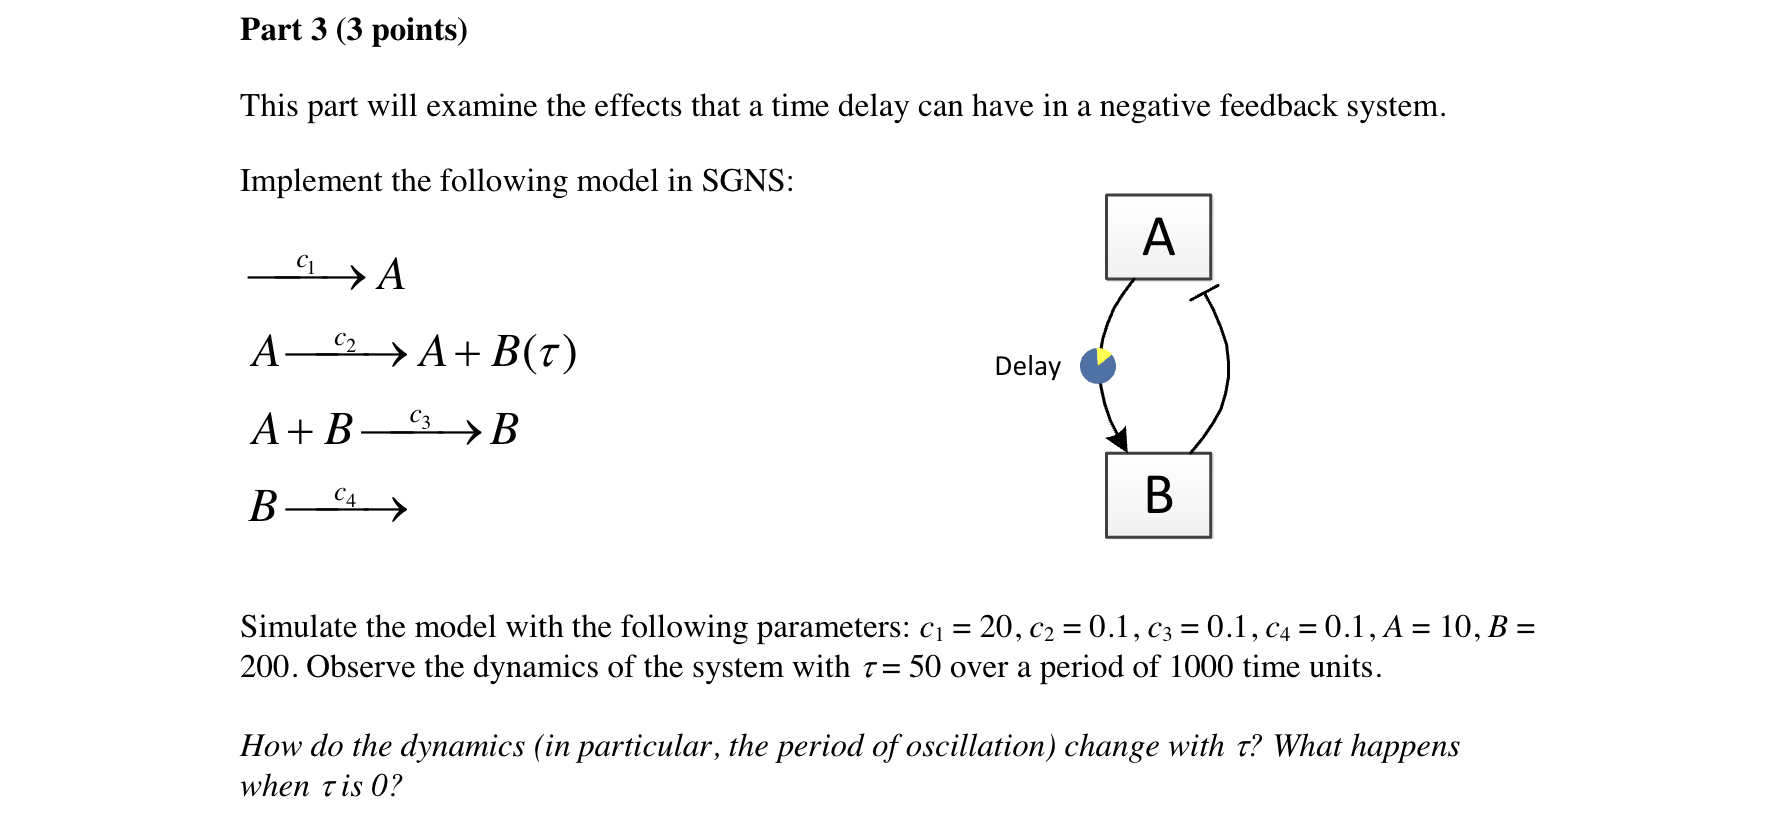

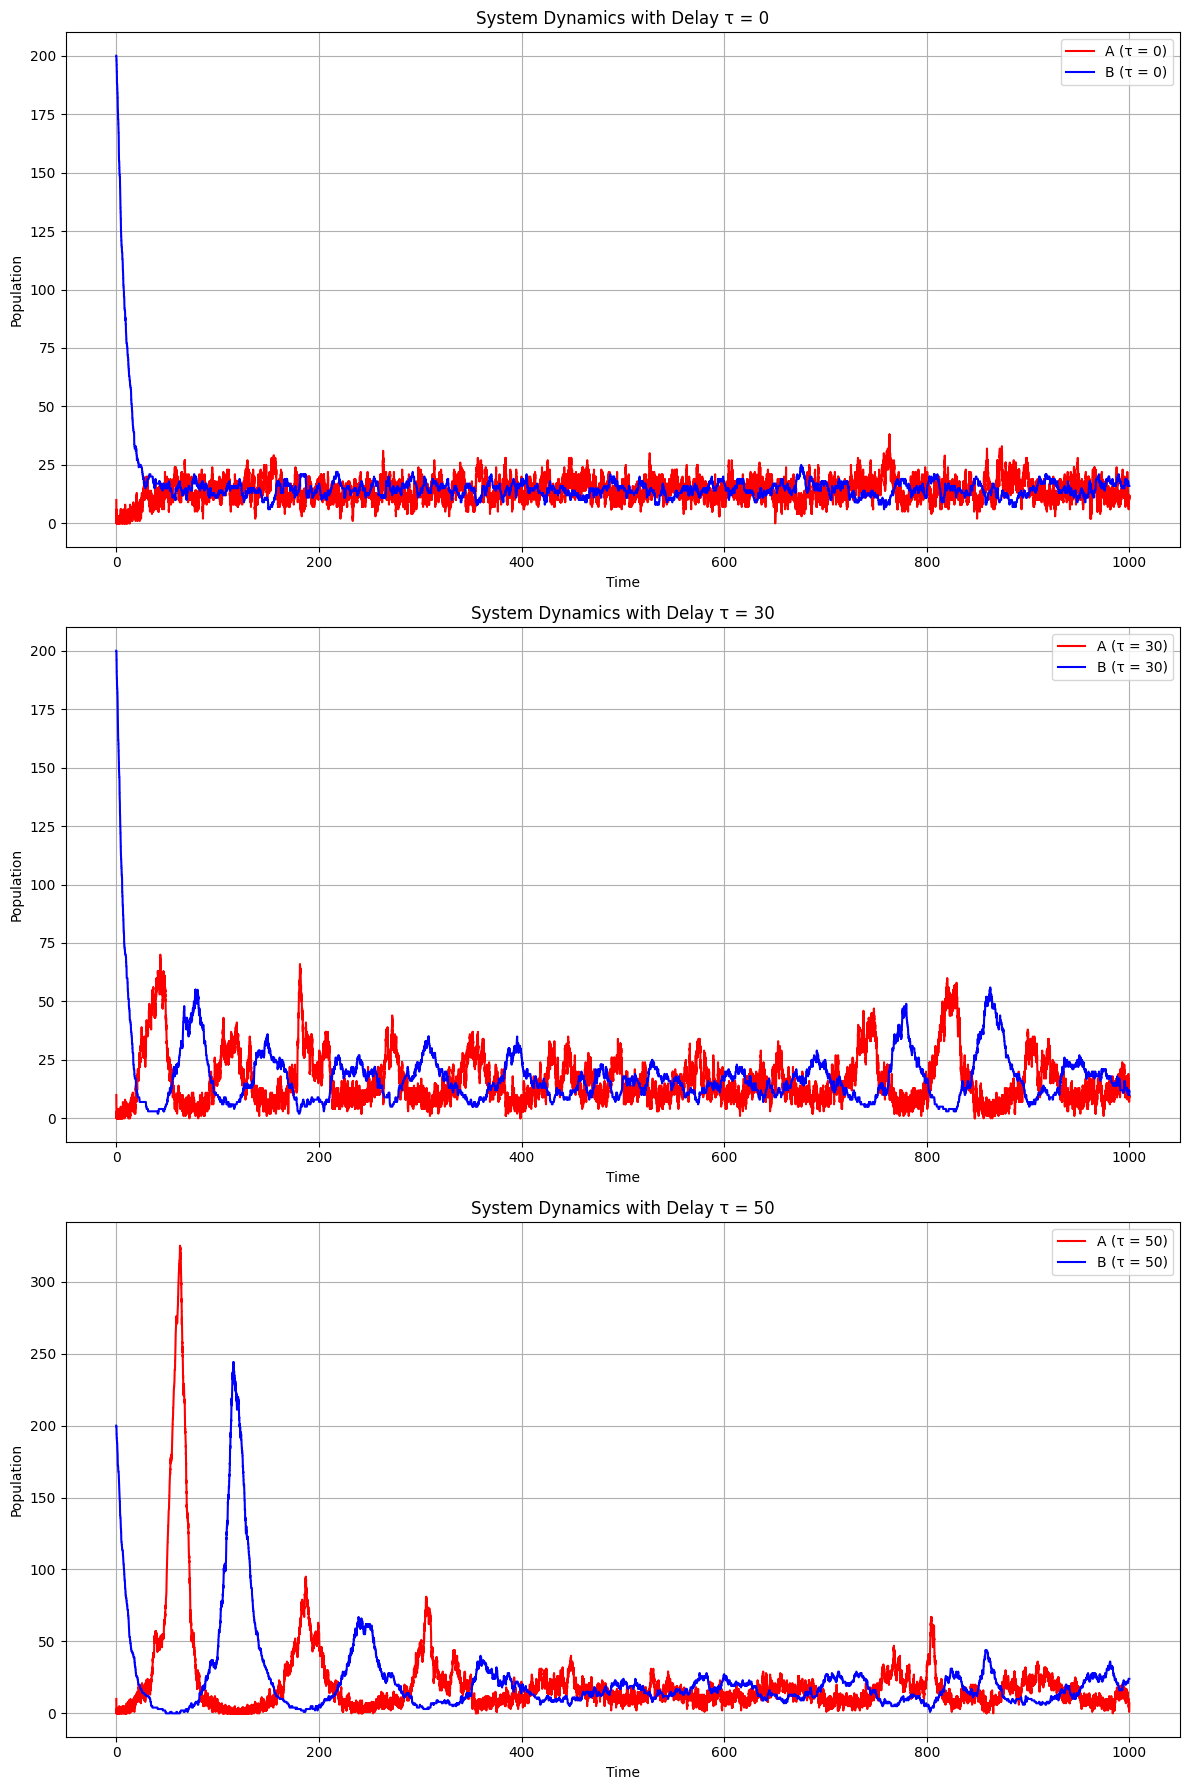

In [27]:
from collections import deque
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
c1 = 20   # Rate of A production
c2 = 0.1  # Rate of B production by A with delay
c3 = 0.1  # Rate of A decay in interaction with B
c4 = 0.1  # Rate of B decay
tau = 50  # Delay for reaction A -> B
time_end = 1000  # Total simulation time

# Gillespie algorithm with delay
def gillespie_with_delay(A0, B0, c1, c2, c3, c4, tau, time_end):
    # Initialize time and population counts
    times = [0]
    A_counts = [A0]
    B_counts = [B0]

    A = A0
    B = B0
    time = 0

    # Queue to manage delayed reaction
    delayed_events = deque()

    while time < time_end:
        # Calculate reaction rates
        r1 = c1                       # Production of A
        r2 = c2 * A                   # Delayed production of B (initiated by A)
        r3 = c3 * A * B               # Interaction between A and B
        r4 = c4 * B                   # Decay of B

        # Total rate
        total_rate = r1 + r2 + r3 + r4

        # If no more reactions are possible
        if total_rate == 0:
            break

        # Time to next reaction
        tau_next = -np.log(np.random.rand()) / total_rate
        time += tau_next

        # Check if it's time to process a delayed event
        while delayed_events and delayed_events[0][0] <= time:
            _, delayed_B_production = delayed_events.popleft()
            B += delayed_B_production

        # Determine which reaction occurs
        prob = np.random.rand() * total_rate

        if prob < r1:
            A += 1  # Reaction: Production of A
        elif prob < r1 + r2:
            delayed_events.append((time + tau, 1))  # Reaction: Production of B with delay
        elif prob < r1 + r2 + r3:
            if A > 0 and B > 0:
                A -= 1  # Reaction: Decay of A due to interaction with B
        else:
            if B > 0:
                B -= 1  # Reaction: Decay of B

        # Record the state
        times.append(time)
        A_counts.append(A)
        B_counts.append(B)

    return np.array(times), np.array(A_counts), np.array(B_counts)

# Initial conditions
A0 = 10
B0 = 200

# Run simulation
times, A_counts, B_counts = gillespie_with_delay(A0, B0, c1, c2, c3, c4, tau, time_end)

tau_values = [0, 30, 50]

# Plot results for different delays
plt.figure(figsize=(12, 18))

for i, tau in enumerate(tau_values):
    times, A_counts, B_counts = gillespie_with_delay(A0, B0, c1, c2, c3, c4, tau, time_end)

    plt.subplot(3, 1, i + 1)
    plt.plot(times, A_counts, label=f'A (τ = {tau})', color='r')
    plt.plot(times, B_counts, label=f'B (τ = {tau})', color='b')
    plt.xlabel('Time')
    plt.ylabel('Population')
    plt.title(f'System Dynamics with Delay τ = {tau}')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

### Part 3: Effects of Time Delay on a Negative Feedback System

**Question 1: How do the dynamics, particularly the period of oscillation, change with τ?**

As the time delay (τ) increases, the system exhibits more pronounced oscillations in the populations of molecules A and B. At τ = 30, moderate fluctuations occur, while τ = 50 produces larger oscillations with more widely spaced prominent peaks, particularly early in the simulation. This suggests that increasing the delay can lengthen the oscillation period and increase the amplitude of population fluctuations. However, because the simulation is stochastic and the oscillations are irregular, an exact period cannot be determined reliably from these graphs alone.

**Question 2: What happens when τ is 0?**

When τ = 0, the production of molecule B occurs without an imposed delay, allowing negative feedback to respond more quickly to changes in molecule A. The simulation shows that after an initial adjustment, both populations remain relatively stable with small, irregular fluctuations rather than large, sustained oscillations. This suggests that removing the delay reduces the pronounced oscillatory behavior observed when τ = 30 and τ = 50.